# 03 · YOLO (one-stage, anchor-free)

Rubric: *One-stage Anchor-free*. Same protocol as every other model: 3-fold GroupKFold by clip
(`splits.json`), train frames every 20th frame, validation frames every 10th frame, 640 px,
12 epochs, OOF COCO metrics with ignored regions as `iscrowd=1` (`common.evaluate`).

Data conversion, training, prediction and logging live in `ul_dataset.py` (shared with RT-DETR);
metrics and the submission writer in `common.py`.

How to run: set `MODE`, `EXPERIMENT` and `FOLDS` below.
- `quick` — 2 clips per fold part, 1 epoch: checks every code path in a few minutes;
- `full` — trains one experiment on all folds (one experiment per Kaggle commit);
- `submit` — trains on all 63 clips and writes `submission.csv` (leaderboard run, not a comparison run).

## 1. Run configuration

In [1]:
MODE = "full"            # "quick" | "full" | "submit"
EXPERIMENT = "yolo_1024"  # key of EXPERIMENTS (section 3)
FOLDS = [0, 1, 2]
REDO_FOLDS = []           # folds to retrain even if an attached output already has them (e.g. [2])
SUBMIT_EPOCHS = 20        # submit mode only
SUBMIT_STRIDE = 10        # submit mode only: train frame stride over all clips
SUBMIT_IMGSZ = 1024       # submit mode only: input size (small objects gain most from resolution)
SUBMIT_BATCH = 8          # submit mode only: lower batch for larger inputs (T4 16 GB)

## 2. Setup
Install Ultralytics and get the shared modules (next to this notebook, an attached Kaggle Dataset, or the GitHub repo).

In [2]:
import os, sys, shutil, subprocess, time, urllib.request
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"   # no per-layer / per-batch printouts in the notebook
try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--timeout", "60", "--retries", "5",
                    "ultralytics==8.4.203", "pycocotools"], check=True, timeout=1800)
    import ultralytics
os.environ["WANDB_MODE"] = "disabled"   # switch on later for the W&B bonus

REPO_RAW = "https://raw.githubusercontent.com/KaplyshOlha/hw-2/main/notebooks/"

def fetch(url, dst, timeout=60, tries=5):
    # download with a timeout and retries: a stalled GitHub request must not hang a commit for hours
    for i in range(tries):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                Path(dst).write_bytes(r.read())
            return dst
        except Exception as e:
            if i == tries - 1:
                raise
            print(f"{url}: {type(e).__name__}, retry in 30 s"); time.sleep(30)
SRC_FILES = ["common.py", "ul_dataset.py", "splits.json"]
common_slug = "multiple-object-video-detection-hw-2-ucu-ai-2026"
SRC = next((Path(p) for p in [".", "notebooks"] if all((Path(p) / f).exists() for f in SRC_FILES)), None)
if SRC is None:
    SRC = Path("/tmp/hw2_src"); SRC.mkdir(exist_ok=True)
    for f in SRC_FILES:
        # depth-limited search in attached datasets only (never scan the 77k competition files)
        found = [p for pat in ["*", "*/*", "*/*/*"] for p in sorted(Path("/kaggle/input").glob(f"{pat}/{f}"))
                 if "competitions" not in p.parts and common_slug not in p.parts] if Path("/kaggle/input").exists() else []
        if found:
            shutil.copy(found[0], SRC / f)
        else:
            fetch(REPO_RAW + f, SRC / f)
sys.path.insert(0, str(SRC))
print("ultralytics", ultralytics.__version__, "| sources:", SRC.resolve())

ultralytics 8.4.203 | sources: /tmp/hw2_src


Imports, output paths and device. FULL / SUBMIT modes stop immediately if no GPU is attached.

In [3]:
import importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from IPython.display import display

import common, ul_dataset as uld
importlib.reload(common); importlib.reload(uld)

assert MODE in ("quick", "full", "submit")
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
RUN_ROOT = WORK / ("ul_runs" if MODE != "quick" else "ul_runs_quick")
RESULTS = WORK / ("results.csv" if MODE != "quick" else "results_quick.csv")
DATA_ROOT = Path("/tmp/ul_data")            # converted frames (not saved as notebook output)
IMG_DIR = WORK / "images"
for p in (RUN_ROOT, IMG_DIR):
    p.mkdir(parents=True, exist_ok=True)
if MODE != "quick":
    assert torch.cuda.is_available(), "attach a GPU (Settings -> Accelerator)"
DEVICE = "0" if torch.cuda.is_available() else "cpu"
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
uld.restore_from_inputs(RUN_ROOT);

device: Tesla T4
restored 6 finished folds from /kaggle/input


## 3. Experiments
All runs share the protocol in `uld.Config`: YOLOv8s COCO weights, 640 px, 12 epochs, batch 16,
SGD (lr0 0.01, momentum 0.937, wd 5e-4, 1 warmup epoch), Ultralytics default augmentation
(mosaic, HSV, scale 0.5, h-flip) with mosaic switched off for the last 3 epochs, AMP, seed 42.
Train frames have ignored regions painted gray; validation frames are the raw frames, like test.
Inference: `conf=0.001`, NMS IoU 0.7, `max_det=300`; metrics on the last epoch's weights.

| experiment | change | motivation |
|---|---|---|
| `yolo_base` | YOLOv8s defaults | reference |
| `yolo_p2` | extra P2 head (stride 4), `yolov8s-p2.yaml`; backbone from YOLOv8s (219/437 tensors transfer, neck/head partly new) | EDA: at 640 px the median object is 15 px and 9.7 % are < 8 px, i.e. smaller than the finest default stride (P3 = 8) |
| `yolo_nwd` | box loss 0.5·CIoU + 0.5·NWD | IoU of tiny boxes collapses after a 1–2 px shift; NWD changes smoothly (Wang et al. 2021) |
| `yolo_1024` | input 1024 px, batch 8 | input resolution: at 640 px the median object is 15 px; 1.6× more pixels per object (deviates from the 640 px protocol on purpose) |

Why YOLOv8 and not YOLO11 / YOLO26: Ultralytics ships an official P2 config for v8 (not for 11),
and YOLO26 is NMS-free by default, which would mix two changes when comparing with RT-DETR.

In [4]:
BASE = uld.Config(experiment="yolo_base", model="yolo", weights="yolov8s.pt", device=DEVICE,
                  notes="YOLOv8s, Ultralytics default aug, 640px")
EXPERIMENTS = {
    "yolo_base": BASE,
    "yolo_p2": uld.make_config(BASE, experiment="yolo_p2", arch="yolov8s-p2.yaml",
                               notes="P2 head (stride 4)"),
    "yolo_nwd": uld.make_config(BASE, experiment="yolo_nwd", nwd=0.5, notes="box loss 0.5 CIoU + 0.5 NWD"),
    "yolo_1024": uld.make_config(BASE, experiment="yolo_1024", imgsz=1024, batch=8, pred_batch=8,
                                 notes="input 1024 px (batch 8)"),
}
cfg = EXPERIMENTS[EXPERIMENT]
if MODE == "quick":
    cfg = uld.make_config(cfg, epochs=1, close_mosaic=0, batch=4, workers=2, fps_iters=5, fps_warmup=2)
print(cfg)

Config(experiment='yolo_1024', model='yolo', owner='B', weights='yolov8s.pt', arch='', imgsz=1024, train_stride=20, eval_stride=10, epochs=12, batch=8, optimizer='SGD', lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=1.0, close_mosaic=3, amp=True, cache=False, box=7.5, cls=0.5, dfl=1.5, nwd=0.0, nwd_c=12.8, num_queries=300, backbone_lr_mult=1.0, mosaic=1.0, scale=0.5, fliplr=0.5, conf=0.001, iou=0.7, max_det=300, workers=4, device='0', pred_batch=8, fps_warmup=10, fps_iters=50, notes='input 1024 px (batch 8)')


## 4. Data and folds
All labelled frames (train + val) and the fixed 3-fold split by clip. In QUICK mode each fold keeps 2 train and 2 val clips.

In [5]:
common.seed_everything()
images, anns = common.load_gt(cache="/tmp/gt_cache.pkl")
splits = common.load_splits(SRC / "splits.json")
if MODE == "quick":
    for f in splits["folds"]:
        f["train_clips"], f["val_clips"] = f["train_clips"][:2], f["val_clips"][:2]
conv = uld.Converter(images, anns, DATA_ROOT)
pd.DataFrame([{"fold": f["fold"], "train_clips": len(f["train_clips"]), "val_clips": len(f["val_clips"]),
               "train_frames": len(common.fold_images(images, splits, f["fold"], "train", cfg.train_stride)),
               "val_frames": len(common.fold_images(images, splits, f["fold"], "val", cfg.eval_stride))}
              for f in splits["folds"]]).set_index("fold")

,train_clips,val_clips,train_frames,val_frames
fold,,,,
0,42,21,922,912
1,42,21,923,913
2,42,21,923,909


### 4.1 Conversion check
Fold 0 is converted once, then YOLO label files are read back **from disk** and drawn on the stored
images: a filled train frame (gray = ignored region, boxes mostly inside it are dropped) and a raw
validation frame. This verifies the normalised `class cx cy w h` conversion end to end.

141 of 922 fold-0 train frames lost boxes to ignored regions (606 boxes of 38923)


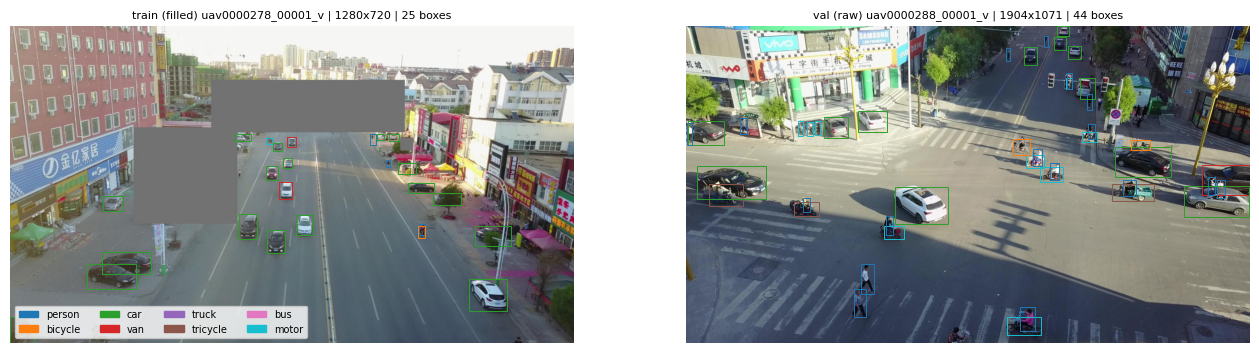

train frame: 25 label rows vs 70 GT boxes (difference = boxes >=50% inside ignore)
val frame:   44 label rows vs 44 GT boxes


In [6]:
yaml0, tr0, va0 = uld.prepare_fold(conv, splits, 0, cfg)
COLORS = plt.cm.tab10([0, 1, 2, 3, 4, 5, 6, 9])  # skip tab10 gray (7): it looks like the ignore fill

def draw_yolo(ax, img_path, title):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lab = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
    rows = np.loadtxt(lab, ndmin=2) if lab.stat().st_size else np.zeros((0, 5))
    ax.imshow(img)
    for c, cx, cy, bw, bh in rows:
        ax.add_patch(mpatches.Rectangle(((cx - bw / 2) * w, (cy - bh / 2) * h), bw * w, bh * h,
                                        fill=False, ec=COLORS[int(c)], lw=0.7))
    ax.set_title(f"{title} | {w}x{h} | {len(rows)} boxes", fontsize=8); ax.axis("off")
    return len(rows)

# train frame where the >=50 % rule dropped most boxes (falls back to most ignored regions)
n_gt = anns[anns.iscrowd == 0].groupby("img_id").size().reindex(tr0.img_id, fill_value=0)
def n_label_rows(i):
    lab = Path(str(conv.path(i, "filled")).replace("/images/", "/labels/")).with_suffix(".txt")
    return sum(1 for line in lab.read_text().splitlines() if line.strip()) if lab.exists() else 0
n_lab = pd.Series({i: n_label_rows(i) for i in tr0.img_id})
dropped = (n_gt - n_lab.reindex(n_gt.index)).clip(lower=0)
n_ign = anns[anns.iscrowd == 1].groupby("img_id").size().reindex(tr0.img_id, fill_value=0)
pick_tr = dropped.idxmax() if dropped.max() > 0 else n_ign.idxmax()
print(f"{int((dropped > 0).sum())} of {len(tr0)} fold-0 train frames lost boxes to ignored regions "
      f"({int(dropped.sum())} boxes of {int(n_gt.sum())})")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
n_tr = draw_yolo(axes[0], conv.path(pick_tr, "filled"), f"train (filled) {images.at[pick_tr, 'clip']}")
pick_va = int(va0.img_id.iloc[len(va0) // 2])
n_va = draw_yolo(axes[1], conv.path(pick_va, "raw"), f"val (raw) {images.at[pick_va, 'clip']}")
axes[0].legend(handles=[mpatches.Patch(color=COLORS[i], label=c) for i, c in enumerate(common.CLASSES)],
               fontsize=7, ncol=4, loc="lower left")
fig.savefig(IMG_DIR / "03_yolo_conversion_check.png"); plt.show()

gt_tr = int(((anns.img_id == pick_tr) & (anns.iscrowd == 0)).sum())
gt_va = int(((anns.img_id == pick_va) & (anns.iscrowd == 0)).sum())
print(f"train frame: {n_tr} label rows vs {gt_tr} GT boxes (difference = boxes >=50% inside ignore)")
print(f"val frame:   {n_va} label rows vs {gt_va} GT boxes")

**Observations (conversion):** TBD

Round-trip check of the coordinates: label files of 50 validation frames are converted back to
original pixels and scored with `common.evaluate` as if they were predictions (should be ≈ 1).

In [7]:
rows = []
for iid in va0.img_id.iloc[:: max(1, len(va0) // 50)]:
    w, h = images.at[iid, "width"], images.at[iid, "height"]
    lab = Path(str(conv.path(iid, "raw")).replace("/images/", "/labels/")).with_suffix(".txt")
    a = np.loadtxt(lab, ndmin=2) if lab.stat().st_size else np.zeros((0, 5))
    rows.append(pd.DataFrame({"img_id": iid, "cls": a[:, 0].astype(int), "score": 1.0,
                              "x": (a[:, 1] - a[:, 3] / 2) * w, "y": (a[:, 2] - a[:, 4] / 2) * h,
                              "w": a[:, 3] * w, "h": a[:, 4] * h}))
rt = pd.concat(rows, ignore_index=True)
r = common.evaluate(rt, images, anns, rt.img_id.unique())
print({k: round(r[k], 4) for k in ["mAP", "AP50", "AP_small"]})

{'mAP': 1.0, 'AP50': 1.0, 'AP_small': 1.0}


### 4.2 EDA for anchor-free and query-based detectors
Three checks that Ultralytics-specific choices rest on (CPU, validation-stride frames of all clips,
boxes rescaled to the 640 px input). Boxes mostly inside ignored regions are excluded.

In [8]:
eda_im = common.subsample(images, common.EVAL_STRIDE)
o = anns[(anns.iscrowd == 0) & anns.img_id.isin(eda_im.img_id)].merge(
    images[["img_id", "clip", "width", "height"]], on="img_id")
sc = common.IMGSZ / np.maximum(o.width, o.height)
o = o.assign(cx=(o.x + o.w / 2) * sc, cy=(o.y + o.h / 2) * sc, w640=o.w * sc, h640=o.h * sc)
o["side"] = np.sqrt(o.w640 * o.h640)
o["size_bin"] = pd.cut(o.side, [0, 8, 16, 32, 1e9], labels=["<8", "8-16", "16-32", ">=32"], right=False)
print(f"{eda_im.shape[0]} frames, {len(o)} boxes")

2734 frames, 123834 boxes


**(a) Grid-cell collisions.** An anchor-free head predicts at most one object per location of a
feature map; with task-aligned assignment several GT centres in one cell compete for the same
positives. Share of boxes whose centre shares a cell with another box, per stride
(P2 = 4, P3 = 8, P4 = 16, P5 = 32) and object size.

,stride 4,stride 8,stride 16,stride 32
size_bin,,,,
<8,8.3,28.6,56.8,80.4
8-16,3.1,13.7,37.7,70.4
16-32,0.9,4.5,17.6,48.5
>=32,0.1,0.6,3.5,15.3
all,2.5,10.5,28.8,57.7


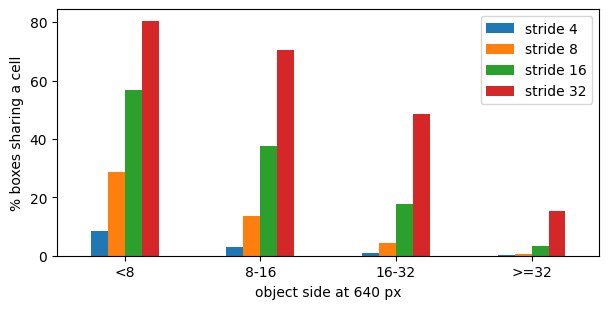

In [9]:
coll = {}
for s in [4, 8, 16, 32]:
    key = o.img_id.astype(str) + "_" + (o.cx // s).astype(int).astype(str) + "_" + (o.cy // s).astype(int).astype(str)
    shared = key.map(key.value_counts()) > 1
    coll[f"stride {s}"] = shared.groupby(o.size_bin, observed=True).mean().mul(100)
    coll[f"stride {s}"]["all"] = 100 * shared.mean()
coll = pd.DataFrame(coll).round(1)
display(coll)
fig, ax = plt.subplots(figsize=(7, 3.2))
coll.drop(index="all").plot.bar(ax=ax, rot=0)
ax.set_ylabel("% boxes sharing a cell"); ax.set_xlabel("object side at 640 px")
fig.savefig(IMG_DIR / "03_grid_collisions.png"); plt.show()

**Observations (grid collisions):** TBD

**(b) Overlap between neighbouring GT boxes.** For every box, the highest IoU with another box of
the same class in the same frame. If true neighbours overlap strongly, NMS at that IoU removes
correct detections (relevant for the NMS threshold, Soft-NMS, and for NMS-free RT-DETR).

In [10]:
from torchvision.ops import box_iou
best = np.zeros(len(o))
xyxy = np.column_stack([o.x, o.y, o.x + o.w, o.y + o.h])
for (iid, c), idx in o.groupby(["img_id", "cls"]).indices.items():
    if len(idx) < 2:
        continue
    b = torch.as_tensor(xyxy[idx], dtype=torch.float32)
    iou = box_iou(b, b).fill_diagonal_(0)
    best[idx] = iou.max(1).values.numpy()
o["nn_iou"] = best
thr = [0.3, 0.5, 0.7]
tab = pd.DataFrame({f"IoU>{t}": (o.nn_iou > t).groupby(o.cls.map(dict(enumerate(common.CLASSES)))).mean().mul(100)
                    for t in thr}).reindex(common.CLASSES)
tab.loc["ALL"] = [100 * (o.nn_iou > t).mean() for t in thr]
tab.round(2)

,IoU>0.3,IoU>0.5,IoU>0.7
cls,,,
person,12.00,3.32,0.55
bicycle,3.15,0.38,0.00
car,6.49,0.71,0.12
van,0.15,0.04,0.04
truck,3.03,0.74,0.06
tricycle,1.83,0.29,0.00
bus,0.00,0.00,0.00
motor,2.67,0.48,0.12
ALL,7.12,1.44,0.24


**Observations (GT overlap):** TBD

**(c) Scene density vs number of queries.** RT-DETR keeps a fixed set of queries (300 by default)
selected from encoder features; the number of objects per frame bounds how many are needed.

In [11]:
n = o.groupby("img_id").size().reindex(eda_im.img_id, fill_value=0)
fold_of = eda_im.set_index("img_id")["clip"].map(common.clip_to_fold(common.load_splits(SRC / "splits.json")))
dens = n.groupby(fold_of).describe(percentiles=[0.5, 0.9, 0.99])[["mean", "50%", "90%", "99%", "max"]]
dens.index.name = "fold"
dens.loc["all"] = n.describe(percentiles=[0.5, 0.9, 0.99])[["mean", "50%", "90%", "99%", "max"]]
dens["max / 300 queries"] = (dens["max"] / 300).round(2)
dens.round(1)

,mean,50%,90%,99%,max,max / 300 queries
fold,,,,,,
0,51.9,45.0,95.0,150.9,156.0,0.5
1,38.8,28.0,76.0,132.0,161.0,0.5
2,45.3,44.0,87.4,142.0,156.0,0.5
all,45.3,42.0,91.0,141.7,161.0,0.5


**Observations (density vs queries):** TBD

## 5. Train and predict
Every fold in `FOLDS`: convert frames (cached), train with Ultralytics (an interrupted fold resumes
from `last.pt`), predict the fold's raw validation frames, measure FPS at batch 1. OOF metrics are
logged to `results.csv` once all 3 folds are finished.

In [12]:
t0 = time.time()
metrics = None
if MODE != "submit":
    metrics = uld.run_experiment(cfg, images, anns, splits, FOLDS, RUN_ROOT, RESULTS, conv, redo=REDO_FOLDS)
print(f"{(time.time() - t0) / 60:.1f} min")

[yolo_1024] fold 0: 922 train / 912 val frames
yolov8s.pt: copied from /kaggle/input/notebooks/darinopri/notebookd71f8be06d/yolov8s.pt


/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


[yolo_1024] fold 0: 9.3 min, 33.6 FPS
[yolo_1024] fold 1: 923 train / 913 val frames
[yolo_1024] fold 1: 9.1 min, 59.3 FPS
[yolo_1024] fold 2: 923 train / 909 val frames
[yolo_1024] fold 2: 9.6 min, 52.7 FPS
38.6 min


OOF metrics of this experiment: per fold, mean ± std over folds, pooled out-of-fold (`oof`), and per-class OOF AP.

In [13]:
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500"]
PER_CLASS = [f"AP_{c}" for c in common.CLASSES]
if metrics is not None:
    display(metrics[MAIN].round(4))
    display(metrics.loc[["oof"], PER_CLASS].round(4))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500
0,0.1872,0.3521,0.1719,0.0956,0.1582,0.3549,0.3079
1,0.1815,0.3521,0.1661,0.0554,0.1717,0.3248,0.2961
2,0.2138,0.4100,0.1999,0.0626,0.1856,0.3899,0.3538
mean,0.1942,0.3714,0.1793,0.0712,0.1718,0.3565,0.3193
std,0.0141,0.0273,0.0147,0.0175,0.0112,0.0266,0.0249
oof,0.1892,0.3646,0.1735,0.0617,0.1644,0.3498,0.3160


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
oof,0.2173,0.054,0.4491,0.1298,0.0829,0.1688,0.3009,0.1209


## 6. Comparison of experiments
Latest logged run of every YOLO experiment (OOF and mean ± std over folds) from this session, attached outputs of earlier versions and the repo `results.csv`.

In [14]:
def load_all_results():
    # this session + attached notebook outputs + repo copy (dedup by run_id, fold)
    paths = [RESULTS, *uld._input_files("/kaggle/input", "results*.csv")]
    try:
        fetch(REPO_RAW + "results.csv", "/tmp/repo_results.csv", tries=2); paths.append(Path("/tmp/repo_results.csv"))
    except Exception:
        pass
    frames = [pd.read_csv(p) for p in paths if Path(p).exists() and Path(p).stat().st_size
              and (MODE == "quick" or "quick" not in Path(p).name)]
    return pd.concat(frames, ignore_index=True).astype({"fold": str}).drop_duplicates(["run_id", "fold"]) if frames else pd.DataFrame()

def summary(model):
    r = load_all_results()
    if not len(r):
        return pd.DataFrame()
    r = r[r.model == model]
    last = r.sort_values("timestamp").groupby("experiment").run_id.last()
    r = r[r.run_id.isin(last)]
    out = {}
    for e, g in r.groupby("experiment"):
        g = g.set_index("fold")
        out[e] = {**{f"{m}_oof": g.at["oof", m] for m in MAIN},
                  "mAP mean±std": f"{g.at['mean', 'mAP']:.4f} ± {g.at['std', 'mAP']:.4f}",
                  "FPS": g.at["oof", "fps"], "train_min": g.at["oof", "train_min"]}
    return pd.DataFrame(out).T

summ = summary("yolo")
display(summ)

,mAP_oof,AP50_oof,AP75_oof,AP_small_oof,AP_medium_oof,AP_large_oof,AR500_oof,mAP mean±std,FPS,train_min
yolo_1024,0.1892,0.3646,0.1735,0.0617,0.1644,0.3498,0.316,0.1942 ± 0.0141,48.51,28.0
yolo_p2,0.0868,0.1955,0.0698,0.0284,0.089,0.1706,0.1849,0.0888 ± 0.0056,48.96,24.0


Validation mAP@[.5:.95] per epoch (fold 0) from Ultralytics' own validator. This curve is only for
training dynamics (it does not know ignored regions); it is the same quantity for YOLO and RT-DETR,
so it is used for the RT-DETR vs CNN convergence plot.

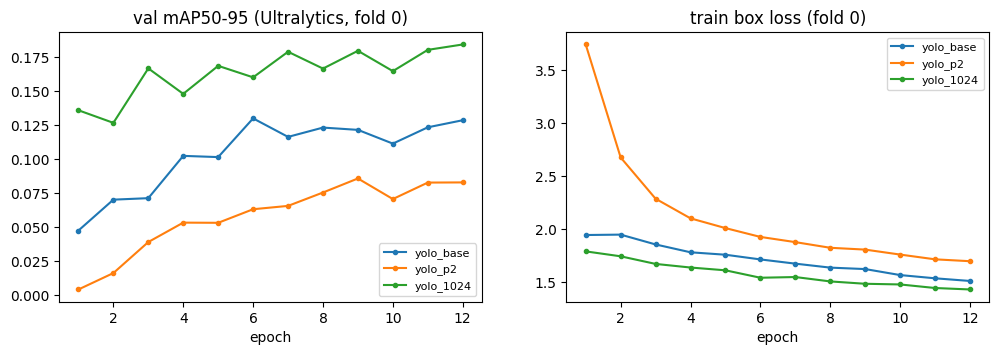

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for e in EXPERIMENTS:
    done = uld.load_done(RUN_ROOT, e)
    if 0 not in done or not done[0]["history"]:
        continue
    h = pd.DataFrame(done[0]["history"])
    ax[0].plot(h["epoch"], h["metrics/mAP50-95(B)"], marker="o", ms=3, label=e)
    ax[1].plot(h["epoch"], h["train/box_loss"], marker="o", ms=3, label=e)
ax[0].set_title("val mAP50-95 (Ultralytics, fold 0)"); ax[1].set_title("train box loss (fold 0)")
for a in ax:
    a.set_xlabel("epoch"); a.legend(fontsize=8)
fig.savefig(IMG_DIR / "03_yolo_curves.png"); plt.show()

**Observations (comparison):** TBD

## 7. Leaderboard submission (`MODE = "submit"`)
Not a comparison run: trains the selected `EXPERIMENT` configuration on all 63 clips (train frames
every `SUBMIT_STRIDE`-th frame) for `SUBMIT_EPOCHS` epochs at `SUBMIT_IMGSZ` px, predicts the 3,811
test frames at the same size and writes `submission.csv`.

In [16]:
if MODE == "submit":
    scfg = uld.make_config(cfg, experiment=f"{cfg.experiment}_all_s{SUBMIT_STRIDE}_e{SUBMIT_EPOCHS}_{SUBMIT_IMGSZ}",
                           train_stride=SUBMIT_STRIDE, epochs=SUBMIT_EPOCHS, imgsz=SUBMIT_IMGSZ,
                           batch=SUBMIT_BATCH, pred_batch=8)
    yaml_all, tr_all, _ = uld.prepare_fold(conv, splits, "all", scfg)
    print(f"training on {len(tr_all)} frames")
    last, minutes = uld.train_fold(scfg, yaml_all, RUN_ROOT / scfg.experiment)
    model = uld.load_trained(scfg, last)
    preds, test_index = uld.predict_test(model, scfg)
    sub_path = common.write_submission(preds, test_index, WORK / "submission.csv")
    sample = next(iter(sorted(common.find_data_root().glob("*sample*submission*.csv"))), None)
    if sample is None:
        sample = WORK / "sample_from_index.csv"
        test_index[["image_id"]].assign(PredictionString="").to_csv(sample, index=False)
    print(f"{minutes:.0f} min training |", common.check_submission(sub_path, sample))

## 8. Outputs
Merge this session's `results.csv` with the repo copy into `results_merged.csv` (commit it as `notebooks/results.csv`).

In [17]:
if MODE == "full" and RESULTS.exists():
    merged = WORK / "results_merged.csv"
    try:
        fetch(REPO_RAW + "results.csv", merged, tries=2)
    except Exception as e:
        print("repo results.csv not available:", e); merged.unlink(missing_ok=True)
    common.merge_results(str(RESULTS), str(merged))
    print(f"{merged}: {len(pd.read_csv(merged))} rows")
for p in sorted(RUN_ROOT.glob("*/fold*/done.json")):
    print(p.parent)

/kaggle/working/results_merged.csv: 18 rows
/kaggle/working/ul_runs/yolo_1024/fold0
/kaggle/working/ul_runs/yolo_1024/fold1
/kaggle/working/ul_runs/yolo_1024/fold2
/kaggle/working/ul_runs/yolo_base/fold0
/kaggle/working/ul_runs/yolo_base/fold1
/kaggle/working/ul_runs/yolo_base/fold2
/kaggle/working/ul_runs/yolo_p2/fold0
/kaggle/working/ul_runs/yolo_p2/fold1
/kaggle/working/ul_runs/yolo_p2/fold2


## 9. Conclusions
TBD